# 5. Facebook vs instagram: how strong is the model, and what does each pipeline stage do?

Facebook and instagram are the two hardest apps. Both are Meta apps, they are rare (11 and 19 of the 330 labelled
flows), and macro F1 weights each of them as much as google (131 flows). This notebook looks **only at these two
apps** and asks three questions:

1. **How separable are they on their own?** A model trained only on the 30 facebook + instagram flows (part 2).
2. **What tells them apart?** The single columns that separate them best (part 3).
3. **How does the production pipeline treat them?** Every stage of the Task 1 and Task 2 production models, traced
   flow by flow on the same 50 cross-validation folds as the champion runs (part 4).
4. **Do engineered or selected features help at this stage?** Engineered features (part 5) and features picked
   inside stratified k-fold (part 6), with importance charts.

Everything uses the 330 labelled train + validation flows with out-of-fold predictions (a flow is always predicted by
a model that never saw it). No test data is used. This is a diagnostic: it changes no model and chooses nothing.
Task 2 analyses read only Task 2 files.

In [1]:
# Setup: find the project root (the folder that holds data/official) and make src/ importable.
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "official").exists())
sys.path.insert(0, str(ROOT / "src"))
os.environ["PYTHONPATH"] = str(ROOT / "src")  # so parallel worker processes can import cv and models

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from matplotlib.colors import ListedColormap
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold

from cv import CV_SEED, TASK_FEATURES, basic_features, load_task
from models import T1_COLS, TASK_MODELS, SoftVote, Task1Bundle, rest_from_columns

META = ["facebook", "instagram"]
FB, IG, OTHER = "#2a78d6", "#eb6834", "#dcdbd5"  # facebook blue, instagram orange, any other app gray
APP_COLOR = {"facebook": FB, "instagram": IG}
INK, MUTED = "#1f2937", "#6b7280"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d1d5db",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10})

## 1. The data

Both tasks describe the **same 330 flows** with the same labels. Task 1 sees the whole flow (34 production columns:
17 whole-flow plus 17 first-5-packet `p5_` columns). Task 2 sees only the first 5 packets (12 production columns, no
timing).

In [2]:
X1_raw, y1 = load_task("task1_static")
X2_raw, y2 = load_task("task2_realtime_prefix5")
assert (X1_raw.flow_id.values == X2_raw.flow_id.values).all() and (y1.values == y2.values).all()
X1 = TASK_FEATURES["task1_static"](X1_raw)            # 34 columns
X2 = TASK_FEATURES["task2_realtime_prefix5"](X2_raw)  # 12 columns
y, flow_ids = np.asarray(y1, dtype=object), X1_raw.flow_id.values
meta = np.isin(y, META)
print(pd.Series(y).value_counts().to_dict())
print(f"Meta flows: {meta.sum()} of {len(y)} (facebook {(y == 'facebook').sum()}, instagram {(y == 'instagram').sum()})")

{'google': 131, 'x': 73, 'youtube': 55, 'mozilla': 41, 'instagram': 19, 'facebook': 11}
Meta flows: 30 of 330 (facebook 11, instagram 19)


## 2. A model that only has to tell facebook from instagram

Here the problem is cut down to two apps. A balanced `SoftVote` (the project's standard model: random forest +
extra trees + LightGBM, probabilities averaged) is trained **only on the 30 Meta flows** and scored with 5-fold
cross-validation repeated 10 times (`cv_seed` 2026). Each test fold holds about 2 facebook and 4 instagram flows.

The scores are computed per repeat over all 30 flows, then averaged over the 10 repeats (± is the std over repeats):

- **F1** for each app with a 0.5 cut-off, and their mean (the two-app macro F1);
- **AUC**: the chance that a random facebook flow gets a higher P(facebook) than a random instagram flow. 1.0 is a
  perfect ranking and 0.5 is a coin toss.

The feature sets show *where* the signal is. The Task 1 opening columns (`p5_`) hold exactly the values of the Task 2
columns, so "Task 2: 12 production columns" also stands for "Task 1 opening only".

In [3]:
def _binary_fold(i, tr, te, X, yb):
    m = SoftVote(seed=i).fit(X.iloc[tr], yb[tr])
    return te, m.predict_proba(X.iloc[te])[:, list(m.classes_).index("facebook")]


def binary_cv(X, yb, n_repeats=10):
    """P(facebook) out of fold, shape (n_repeats, n): balanced SoftVote on facebook vs instagram rows only."""
    splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=n_repeats, random_state=CV_SEED).split(X, yb)
    out = Parallel(n_jobs=-1)(delayed(_binary_fold)(i, tr, te, X, yb) for i, (tr, te) in enumerate(splits))
    P = np.zeros((n_repeats, len(yb)))
    for i, (te, p) in enumerate(out):
        P[i // 5, te] = p
    return P


def binary_scores(P, yb):
    rows = []
    for p in P:  # one repeat = one out-of-fold prediction for every flow
        pred = np.where(p >= 0.5, "facebook", "instagram")
        f = f1_score(yb, pred, labels=META, average=None)
        rows.append({"facebook F1": f[0], "instagram F1": f[1], "macro F1 (2 apps)": f.mean(),
                     "AUC": roc_auc_score(yb == "facebook", p)})
    d = pd.DataFrame(rows)
    return {k: f"{d[k].mean():.3f} ± {d[k].std(ddof=1):.3f}" for k in d}


yb = y[meta]
Xm1, Xm2 = X1[meta].reset_index(drop=True), X2[meta].reset_index(drop=True)
SETS = {
    "Task 1: all 34 production columns": Xm1,
    "Task 1: 17 whole-flow columns": Xm1[list(T1_COLS)],
    "Task 1: 11 rest-of-flow columns (packets 6..N)": rest_from_columns(Xm1),
    "Task 2: 12 production columns (first 5 packets, no timing)": Xm2,
    "Task 2: all 17 columns (with timing)": basic_features(X2_raw)[meta].reset_index(drop=True),
}
PROBS = {name: binary_cv(X, yb) for name, X in SETS.items()}
pd.DataFrame({name: binary_scores(P, yb) for name, P in PROBS.items()}).T

,facebook F1,instagram F1,macro F1 (2 apps),AUC
Task 1: all 34 production columns,0.618 ± 0.097,0.799 ± 0.043,0.708 ± 0.069,0.802 ± 0.047
Task 1: 17 whole-flow columns,0.604 ± 0.097,0.794 ± 0.037,0.699 ± 0.066,0.824 ± 0.040
Task 1: 11 rest-of-flow columns (packets 6..N),0.649 ± 0.070,0.808 ± 0.021,0.729 ± 0.043,0.826 ± 0.032
"Task 2: 12 production columns (first 5 packets, no timing)",0.489 ± 0.065,0.675 ± 0.044,0.582 ± 0.053,0.596 ± 0.049
Task 2: all 17 columns (with timing),0.442 ± 0.093,0.635 ± 0.050,0.538 ± 0.066,0.544 ± 0.072


### Which flows are hard?

Each dot is one Meta flow, placed at its average out-of-fold P(facebook). Facebook flows should sit right of the
dashed 0.5 line and instagram flows left of it. A dot on the wrong side is a flow the two-app model gets wrong.

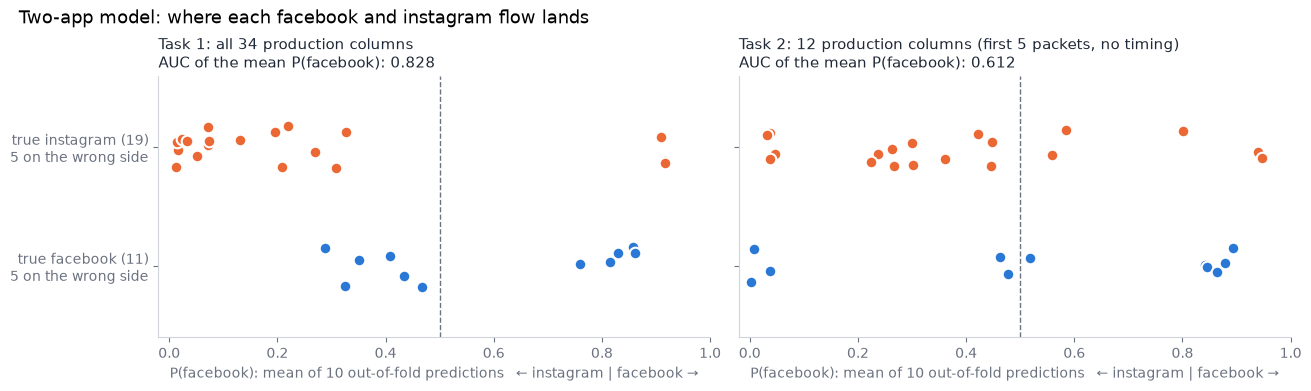

In [4]:
T1_MAIN, T2_MAIN = "Task 1: all 34 production columns", "Task 2: 12 production columns (first 5 packets, no timing)"
rng = np.random.default_rng(0)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True, constrained_layout=True)
for ax, name in zip(axes, [T1_MAIN, T2_MAIN]):
    p = PROBS[name].mean(axis=0)
    for row, app in enumerate(META):
        sel = yb == app
        ax.scatter(p[sel], row + rng.uniform(-0.18, 0.18, sel.sum()), s=70, color=APP_COLOR[app],
                   edgecolor="white", linewidth=1.5, zorder=3)
    ax.axvline(0.5, color=MUTED, lw=1, ls="--", zorder=1)
    wrong = {"facebook": ((yb == "facebook") & (p < 0.5)).sum(), "instagram": ((yb == "instagram") & (p >= 0.5)).sum()}
    ax.set_yticks([0, 1], [f"true {a} ({(yb == a).sum()})\n{wrong[a]} on the wrong side" for a in META])
    ax.set_xlim(-0.02, 1.0)
    ax.set_ylim(-0.6, 1.6)
    ax.set_xlabel("P(facebook): mean of 10 out-of-fold predictions   ← instagram | facebook →")
    ax.set_title(f"{name}\nAUC of the mean P(facebook): {roc_auc_score(yb == 'facebook', p):.3f}", loc="left", fontsize=11, color=INK)
fig.suptitle("Two-app model: where each facebook and instagram flow lands", x=0.01, ha="left", fontsize=13)
plt.show()

## 3. What tells them apart?

For every column, the **single-column AUC** asks how well that column alone ranks facebook above instagram. 0.5 means
no signal. Above 0.5 means facebook tends to have higher values, and below 0.5 means lower. No model is involved. The
strip plots show the four strongest columns per task (log scale), with the other apps in gray for context.

In [5]:
def column_auc(X):
    a = pd.Series({c: roc_auc_score(yb == "facebook", X[c]) for c in X.columns})
    return a.reindex((a - 0.5).abs().sort_values(ascending=False).index)


AUC1, AUC2 = column_auc(Xm1), column_auc(Xm2)
pd.concat({"Task 1 (34 columns)": AUC1.head(8).round(3).reset_index().set_axis(["column", "AUC"], axis=1),
           "Task 2 (12 columns)": AUC2.head(8).round(3).reset_index().set_axis(["column", "AUC"], axis=1)}, axis=1)

Task 1 (34 columns)        Task 2 (12 columns)       
                 column    AUC              column    AUC
0            bytes_down  0.148   std_pkt_size_down  0.258
1     packet_count_down  0.163            bytes_up  0.275
2              bytes_up  0.172           transport  0.344
3           burst_count  0.182    mean_pkt_size_up  0.404
4       packet_count_up  0.194  up_down_byte_ratio  0.414
5  p5_std_pkt_size_down  0.258     std_pkt_size_up  0.455
6           p5_bytes_up  0.275  mean_pkt_size_down  0.538
7              mean_iat  0.718         burst_count  0.519

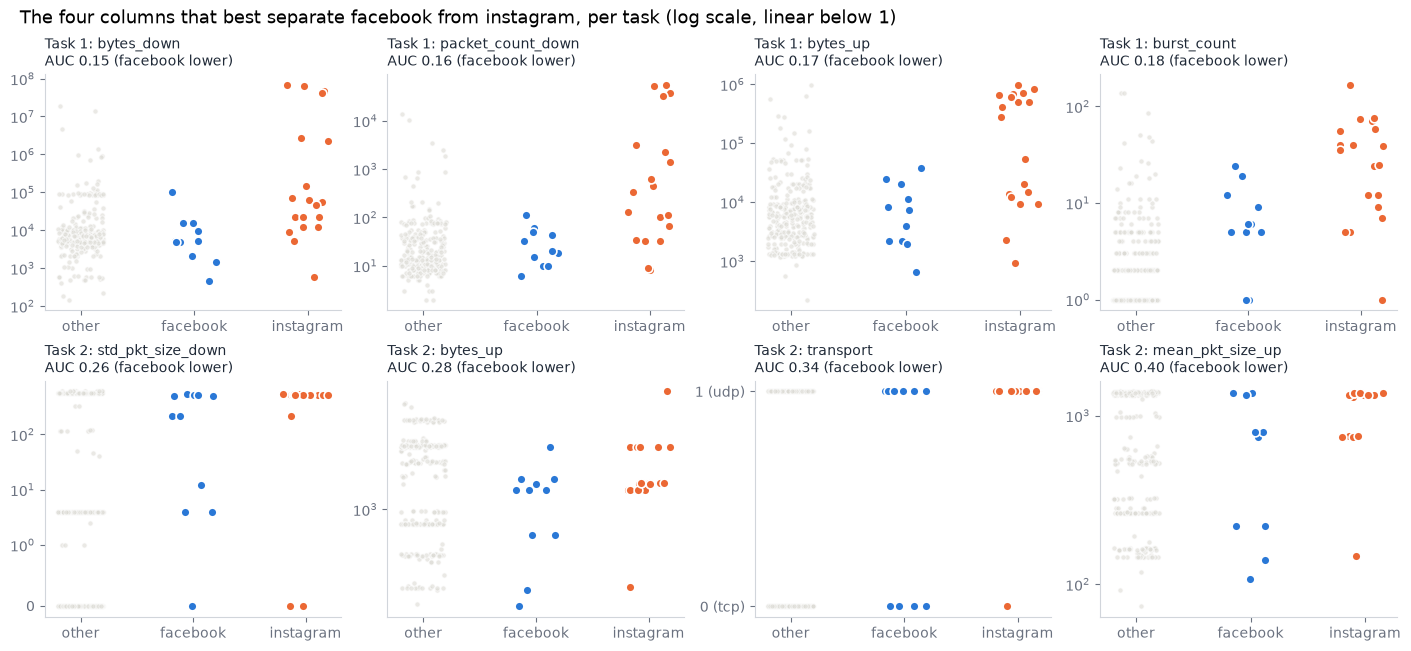

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), constrained_layout=True)
for r, (task, X, auc) in enumerate([("Task 1", X1, AUC1), ("Task 2", X2, AUC2)]):
    for ax, col in zip(axes[r], auc.index[:4]):
        groups = [("other apps", ~meta, OTHER), ("facebook", y == "facebook", FB), ("instagram", y == "instagram", IG)]
        for k, (name, sel, color) in enumerate(groups):
            v = X.loc[sel, col].values.astype(float)
            ax.scatter(k + rng.uniform(-0.2, 0.2, len(v)), v, s=14 if k == 0 else 40,
                       color=color, edgecolor="white", linewidth=0.8 if k == 0 else 1.2, alpha=0.6 if k == 0 else 1)
        if X[col].nunique() <= 2:          # 0/1 column such as transport: plain scale
            ax.set_yticks([0, 1], ["0 (tcp)", "1 (udp)"] if col == "transport" else ["0", "1"])
        else:                              # log scale, linear near 0 so zero values stay visible
            ax.set_yscale("symlog", linthresh=1)
        ax.set_xticks([0, 1, 2], ["other", "facebook", "instagram"])
        ax.set_title(f"{task}: {col}\nAUC {auc[col]:.2f} (facebook {'higher' if auc[col] > 0.5 else 'lower'})", loc="left", fontsize=10, color=INK)
fig.suptitle("The four columns that best separate facebook from instagram, per task (log scale, linear below 1)",
             x=0.01, ha="left", fontsize=13)
plt.show()

## 4. The production pipeline, stage by stage

The production models predict all 6 apps. Below, each stage's prediction is recorded for every held-out flow, on
**exactly the folds and seeds of the champion runs** (`cv_seed` 2026, 5 folds × 10 repeats, model seed = fold
number). The final stage must therefore equal the champion's saved predictions (`oof.csv`), and the code checks
this.

| Stage | Task 1 (`task1_cross_task`, experiment 100) |
|---|---|
| E1 | whole-run expert alone (022) |
| E2 | opening expert alone (12 `p5_` columns) |
| E3 | rest-of-flow expert alone (11 columns, packets 6..N) |
| S1 | two clerks: E1 + E2 averaged, the whole-run expert decides Meta calls (028) |
| S2 | + Meta gate with the rest-of-flow expert and the instagram rule (034, 065, 087) |
| S3 | + google-vs-instagram and google-vs-x verifiers (084) |
| S4 | + exact-opening rule (036) = the 089 bundle |
| S5 | + cross-task rescue (100) = **final** |

| Stage | Task 2 (`task2_model`, experiment 014) |
|---|---|
| T1 | base SoftVote (6 apps) |
| T2 | + facebook/instagram specialist = **final** |

E1 to E3 are experts inside the model, not stages applied one after the other. They are shown to see what each one
knows on its own.

In [7]:
T1_STAGES = ["E1 whole-run expert", "E2 opening expert", "E3 rest-of-flow expert", "S1 two clerks",
             "S2 + Meta gate", "S3 + pair verifiers", "S4 + exact-opening rule", "S5 + cross-task rescue (final)"]
T2_STAGES = ["T1 base SoftVote", "T2 + fb/ig specialist (final)"]


def _trace_fold(task, i, tr, te, X, y):
    m = TASK_MODELS[task](i).fit(X.iloc[tr], y[tr])  # the production model, as cv.evaluate builds it for fold i
    Xte = X.iloc[te]
    if task == "task1_static":
        Xr = Task1Bundle._with_rest(Xte)               # 34 columns + 11 rest-of-flow columns
        h1 = m.t1_.model_                              # ScopedH1 (036) around ...
        bv = h1.model_                                 # BundleVerifiers (084) around ...
        gate = bv.base_                                # RestIGMetaGate (034 + 065 + 087) around ...
        clerks = gate.clerks_                          # TwoClerks (028)
        Xb = Xr[gate.base_cols_]
        preds = [clerks.whole_.predict(Xb), clerks.opening_.predict(Xb[list(clerks.OPEN_COLS)]),
                 gate.rest_.predict(Xr[list(rest_from_columns(Xte).columns)]), clerks.predict(Xb),
                 gate.predict(Xr), bv.predict(Xr), h1.predict(Xr), m.predict(Xte)]
        stages = T1_STAGES
    else:
        preds, stages = [m.base_.predict(Xte[m.base_cols_]), m.predict(Xte)], T2_STAGES
    df = pd.DataFrame({s: np.asarray(p, dtype=object) for s, p in zip(stages, preds)})
    df.insert(0, "y_true", y[te])
    df.insert(0, "flow_id", flow_ids[te])
    df.insert(0, "fold", i)
    return df


def trace(task, X):
    splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=CV_SEED).split(X, y)
    out = Parallel(n_jobs=-1)(delayed(_trace_fold)(task, i, tr, te, X, y) for i, (tr, te) in enumerate(splits))
    t = pd.concat(out, ignore_index=True)
    champion = pd.read_json(ROOT / "results" / "champions.json")[task]["run_id"]
    oof = pd.read_csv(ROOT / "results" / champion / task / "oof.csv")
    final = (T1_STAGES if task == "task1_static" else T2_STAGES)[-1]
    assert (oof.flow_id.values == t.flow_id.values).all() and (oof.y_pred.values == t[final].values).all()
    print(f"{task}: final stage reproduces champion run {champion} exactly ({len(t)} predictions)")
    return t


TR1 = trace("task1_static", X1)
TR2 = trace("task2_realtime_prefix5", X2)

task1_static: final stage reproduces champion run 20261012T154049Z_100_production_check_s2026 exactly (3300 predictions)


task2_realtime_prefix5: final stage reproduces champion run 20260930T173836Z_014_fi_same_nocw exactly (3300 predictions)


### Scores per stage

Pooled over all 50 folds (each flow predicted 10 times). The last three columns count flows **per repeat**, out of
30 Meta flows or 300 other flows:

- **sent outside Meta**: a facebook/instagram flow called google, youtube, etc.;
- **fb↔ig swaps**: a facebook flow called instagram or the other way round;
- **pulled into Meta**: another app's flow called facebook or instagram (a false alarm).

In [8]:
def stage_table(t, stages):
    rows = []
    yt = t.y_true.values
    for s in stages:
        yp = t[s].values
        f = f1_score(yt, yp, labels=META, average=None, zero_division=0)
        rec = [((yt == a) & (yp == a)).sum() / (yt == a).sum() for a in META]
        pre = [((yt == a) & (yp == a)).sum() / max((yp == a).sum(), 1) for a in META]
        rows.append({"stage": s, "facebook F1": f[0], "instagram F1": f[1],
                     "facebook recall": rec[0], "facebook precision": pre[0],
                     "instagram recall": rec[1], "instagram precision": pre[1],
                     "sent outside Meta": (np.isin(yt, META) & ~np.isin(yp, META)).sum() / 10,
                     "fb↔ig swaps": (np.isin(yt, META) & np.isin(yp, META) & (yt != yp)).sum() / 10,
                     "pulled into Meta": (~np.isin(yt, META) & np.isin(yp, META)).sum() / 10})
    return pd.DataFrame(rows).set_index("stage").round(3)


ST1, ST2 = stage_table(TR1, T1_STAGES), stage_table(TR2, T2_STAGES)
pd.concat({"Task 1": ST1, "Task 2": ST2})

facebook F1  instagram F1  \
       stage                                                       
Task 1 E1 whole-run expert                   0.628         0.778   
       E2 opening expert                     0.438         0.658   
       E3 rest-of-flow expert                0.560         0.579   
       S1 two clerks                         0.628         0.778   
       S2 + Meta gate                        0.690         0.778   
       S3 + pair verifiers                   0.690         0.785   
       S4 + exact-opening rule               0.690         0.785   
       S5 + cross-task rescue (final)        0.722         0.785   
Task 2 T1 base SoftVote                      0.438         0.658   
       T2 + fb/ig specialist (final)         0.469         0.731   

                                       facebook recall  facebook precision  \
       stage                                                                 
Task 1 E1 whole-run expert                       0.591               0.670   
       E2 opening expert                         0.418               0.460   
       E3 rest-of-flow expert                    0.491               0.651   
       S1 two clerks                             0.591               0.670   
       S2 + Meta gate                            0.718               0.664   
       S3 + pair verifiers                       0.718               0.664   
       S4 + exact-opening rule                   0.718               0.664   
       S5 + cross-task rescue (final)            0.791               0.664   
Task 2 T1 base SoftVote                          0.418               0.460   
       T2 + fb/ig specialist (final)             0.418               0.535   

                                       instagram recall  instagram precision  \
       stage                                                                   
Task 1 E1 whole-run expert                        0.747                0.811   
       E2 opening expert                          0.653                0.663   
       E3 rest-of-flow expert                     0.558                0.602   
       S1 two clerks                              0.747                0.811   
       S2 + Meta gate                             0.747                0.811   
       S3 + pair verifiers                        0.732                0.848   
       S4 + exact-opening rule                    0.732                0.848   
       S5 + cross-task rescue (final)             0.732                0.848   
Task 2 T1 base SoftVote                           0.653                0.663   
       T2 + fb/ig specialist (final)              0.753                0.711   

                                       sent outside Meta  fb↔ig swaps  \
       stage                                                            
Task 1 E1 whole-run expert                           5.7          3.6   
       E2 opening expert                             3.4          9.6   
       E3 rest-of-flow expert                       12.1          1.9   
       S1 two clerks                                 5.7          3.6   
       S2 + Meta gate                                3.9          4.0   
       S3 + pair verifiers                           4.2          4.0   
       S4 + exact-opening rule                       4.2          4.0   
       S5 + cross-task rescue (final)                3.0          4.4   
Task 2 T1 base SoftVote                              3.4          9.6   
       T2 + fb/ig specialist (final)                 3.4          7.7   

                                       pulled into Meta  
       stage                                             
Task 1 E1 whole-run expert                          2.9  
       E2 opening expert                            2.1  
       E3 rest-of-flow expert                       8.0  
       S1 two clerks                                2.9  
       S2 + Meta gate                               3.3  
       S3 + pair verifiers               

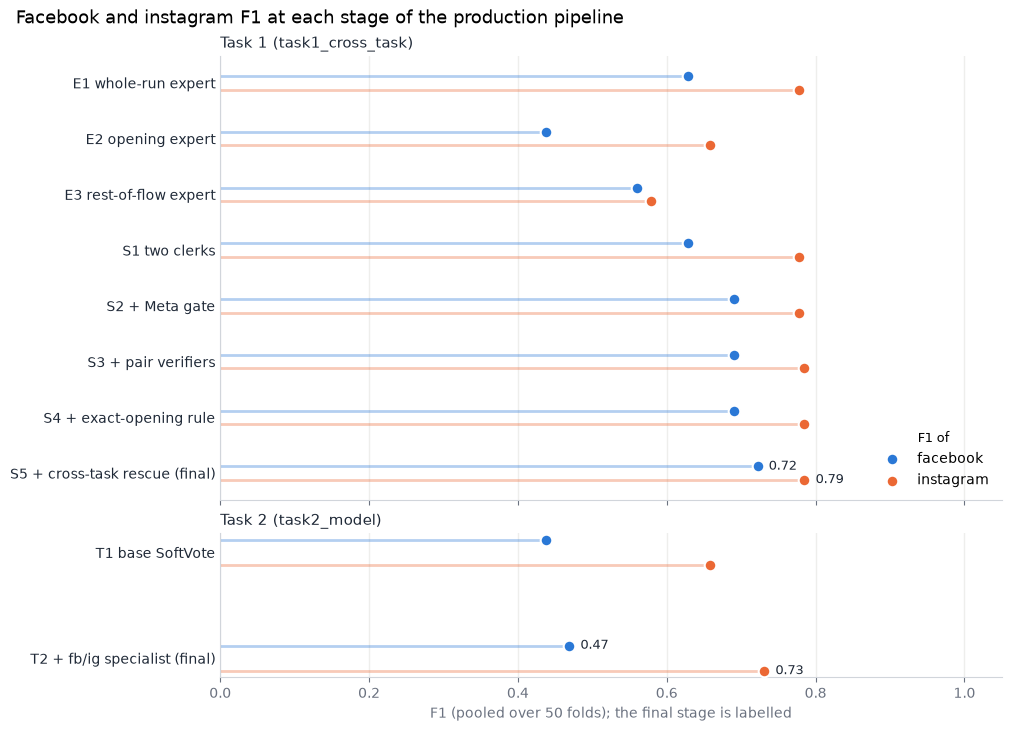

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7.2), sharex=True, constrained_layout=True,
                         gridspec_kw={"height_ratios": [len(T1_STAGES), len(T2_STAGES) + 0.6]})
for ax, (task, st) in zip(axes, [("Task 1 (task1_cross_task)", ST1), ("Task 2 (task2_model)", ST2)]):
    ypos = np.arange(len(st))[::-1]
    for app, color, dy in (("facebook", FB, 0.12), ("instagram", IG, -0.12)):
        v = st[f"{app} F1"].values
        ax.hlines(ypos + dy, 0, v, color=color, lw=2, alpha=0.35)
        ax.scatter(v, ypos + dy, s=70, color=color, edgecolor="white", linewidth=1.5, zorder=3, label=app)
        ax.text(v[-1] + 0.015, ypos[-1] + dy, f"{v[-1]:.2f}", va="center", fontsize=9, color=INK)
    ax.set_yticks(ypos, st.index)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.set_title(task, loc="left", fontsize=11, color=INK)
    ax.grid(axis="x", color="#eeeeec", lw=1)
    ax.set_axisbelow(True)
axes[0].legend(loc="lower right", frameon=False, title="F1 of", title_fontsize=9)
axes[-1].set_xlim(0, 1.05)
axes[-1].set_xlabel("F1 (pooled over 50 folds); the final stage is labelled")
fig.suptitle("Facebook and instagram F1 at each stage of the production pipeline", x=0.01, ha="left", fontsize=13)
plt.show()

### Each Meta flow's journey through the pipeline

One row per facebook or instagram flow, one column per stage. A cell shows the app that stage gives the flow most
often over the 10 repeats: **blue = facebook**, **orange = instagram**, **gray = another app** (letter: G google,
Y youtube, X x, M mozilla). A row whose colour changes shows a stage changing that flow's prediction. Rows are
sorted by true app, then by how often the final stage is right.

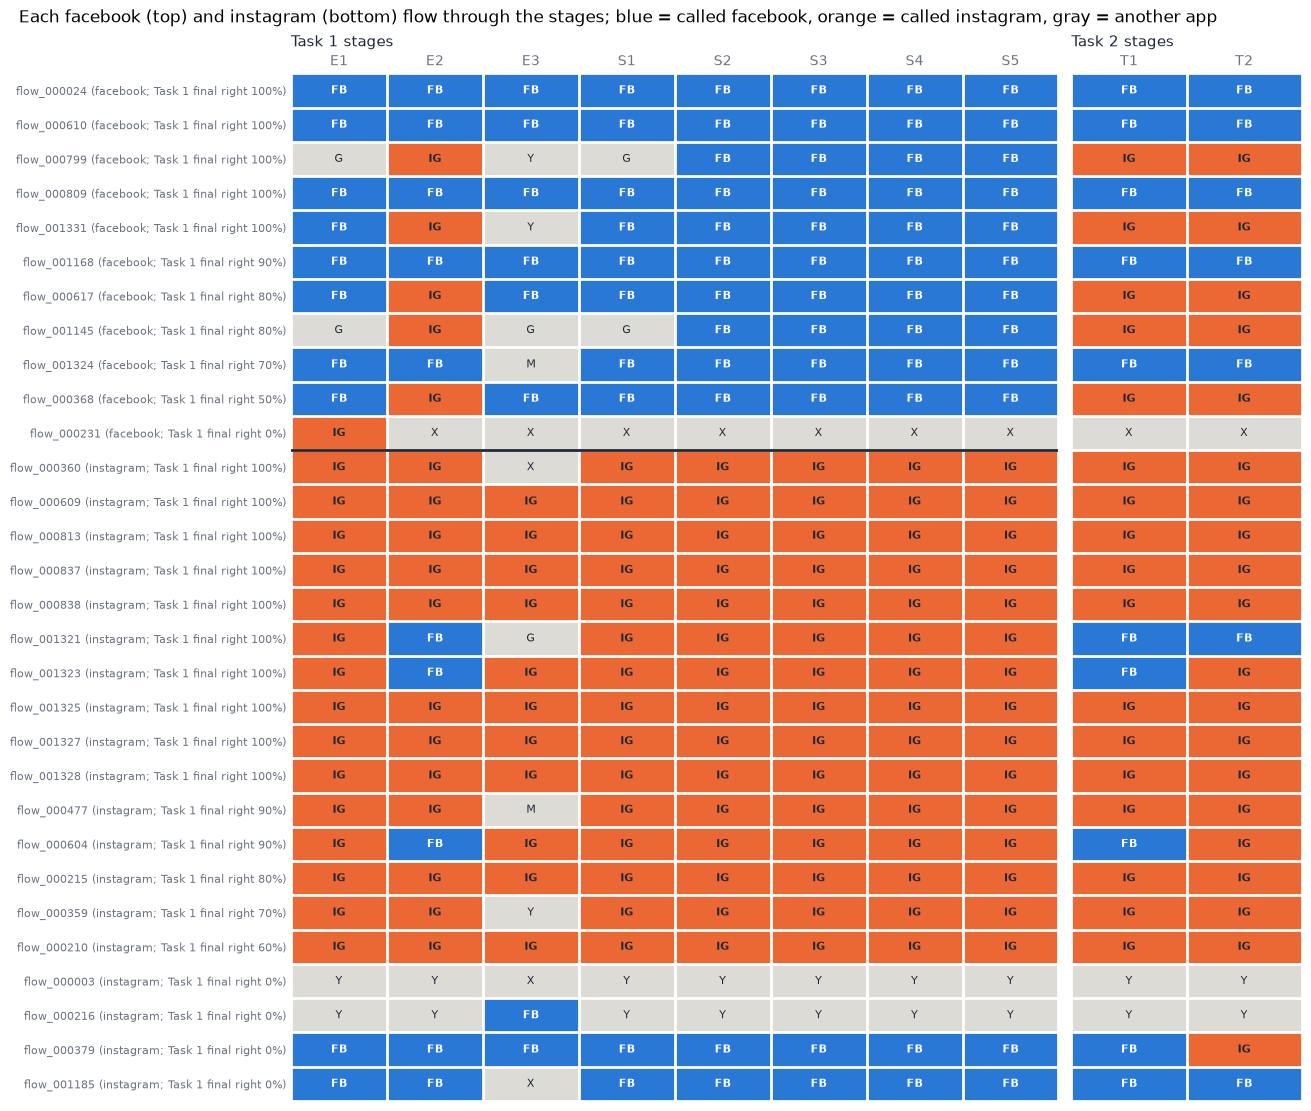

In [10]:
SHORT = {"google": "G", "youtube": "Y", "x": "X", "mozilla": "M", "facebook": "FB", "instagram": "IG"}


def majority(t, stages):
    m = t[np.isin(t.y_true, META)].groupby("flow_id")
    maj = m[stages].agg(lambda s: s.value_counts().idxmax())
    maj["y_true"] = m.y_true.first()
    return maj


J1, J2 = majority(TR1, T1_STAGES), majority(TR2, T2_STAGES)
right = TR1[np.isin(TR1.y_true, META)].assign(ok=lambda d: d[T1_STAGES[-1]] == d.y_true).groupby("flow_id").ok.mean()
order = (pd.DataFrame({"app": J1.y_true, "ok": right}).sort_values(["app", "ok"], ascending=[True, False]).index)
J1, J2 = J1.loc[order], J2.loc[order]

cmap = ListedColormap([FB, IG, OTHER])
code = lambda J, st: J[st].apply(lambda c: c.map(lambda a: 0 if a == "facebook" else 1 if a == "instagram" else 2)).values
fig, axes = plt.subplots(1, 2, figsize=(13, 11), sharey=True, constrained_layout=True,
                         gridspec_kw={"width_ratios": [len(T1_STAGES), len(T2_STAGES) + 0.4]})
for ax, J, st, title in ((axes[0], J1, T1_STAGES, "Task 1 stages"), (axes[1], J2, T2_STAGES, "Task 2 stages")):
    C = code(J, st)
    ax.imshow(C, cmap=cmap, vmin=0, vmax=2, aspect="auto")
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            ax.text(j, i, SHORT[J[st].iat[i, j]], ha="center", va="center", fontsize=8,
                    color="white" if C[i, j] == 0 else INK, fontweight="bold" if C[i, j] < 2 else "normal")
    ax.set_xticks(np.arange(-0.5, len(st)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(J)), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(len(st)), [s.split(" ", 1)[0] for s in st])
    ax.xaxis.tick_top()
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    for s in ax.spines.values():
        s.set_visible(False)
n_fb = (J1.y_true == "facebook").sum()
axes[0].axhline(n_fb - 0.5, color=INK, lw=2)
axes[0].set_yticks(range(len(J1)), [f"{f} ({a}; Task 1 final right {right[f]:.0%})" for f, a in zip(J1.index, J1.y_true)],
                   fontsize=8)
fig.suptitle("Each facebook (top) and instagram (bottom) flow through the stages; blue = called facebook, "
             "orange = called instagram, gray = another app", x=0.01, ha="left", fontsize=12)
plt.show()

### How fragile the facebook score is

With 11 facebook flows, each test fold holds only 2 or 3 of them, so one flow more or less right moves that fold's
facebook F1 by a lot. These are the champion runs' facebook and instagram F1 values in each of the 50 folds.

In [11]:
champions = pd.read_json(ROOT / "results" / "champions.json")
for task in ["task1_static", "task2_realtime_prefix5"]:
    folds = pd.read_csv(ROOT / "results" / champions[task]["run_id"] / task / "folds.csv")
    for app in META:
        v = folds[f"f1_{app}"].round(2).value_counts().sort_index(ascending=False)
        print(f"{task:24s} {app:9s} F1 = 0 in {(folds[f'f1_{app}'] == 0).sum():2d} folds, = 1 in "
              f"{(folds[f'f1_{app}'] == 1).sum():2d} folds; all values:", {k: int(n) for k, n in v.items()})

task1_static             facebook  F1 = 0 in  2 folds, = 1 in 12 folds; all values: {1.0: 12, 0.86: 3, 0.8: 9, 0.67: 17, 0.5: 2, 0.4: 3, 0.33: 2, 0.0: 2}
task1_static             instagram F1 = 0 in  0 folds, = 1 in 12 folds; all values: {1.0: 12, 0.89: 2, 0.86: 6, 0.8: 5, 0.75: 4, 0.67: 15, 0.57: 2, 0.5: 2, 0.33: 2}
task2_realtime_prefix5   facebook  F1 = 0 in 15 folds, = 1 in  2 folds; all values: {1.0: 2, 0.86: 1, 0.8: 1, 0.67: 10, 0.57: 1, 0.5: 17, 0.4: 2, 0.29: 1, 0.0: 15}
task2_realtime_prefix5   instagram F1 = 0 in  2 folds, = 1 in  0 folds; all values: {0.89: 7, 0.86: 3, 0.8: 8, 0.75: 13, 0.73: 1, 0.67: 9, 0.57: 3, 0.5: 2, 0.4: 2, 0.0: 2}


## 5. Feature engineering at the facebook/instagram stage

The earlier tests of engineered features (experiments 008 and 029) were run on the **6-app** model. A feature that
only matters for facebook vs instagram can get lost there: 30 Meta flows among 330, and five other apps pulling the
trees elsewhere. So this part tests engineered features **where the decision is made**, in the two-app model of part
2 (30 flows, same 50 folds).

The features are fixed here, from what each column means, **before** any result is seen. Each one combines given
columns in a way a tree cannot easily form by itself (ratios, rates, per-burst amounts, contrasts between the
opening and the rest of the flow). Divisions by zero give 0. Prefix `e_` = engineered, `r_` = rest-of-flow
(packets 6..N, notebook 1).

| Family | Task 1 features | Task 2 features (Task 2 columns only) |
|---|---|---|
| Totals | `e_total_bytes`, `e_total_pkts` | `e_total_bytes`, `e_total_pkts` |
| Direction | `e_down_byte_share`, `e_down_pkt_share`, `e_size_asym` (mean size down − up) | same |
| Rates | `e_rate_down`, `e_rate_up`, `e_pkt_rate` (per second) | — (no timing in Task 2) |
| Bursts | `e_bytes_per_burst`, `e_pkts_per_burst`, `e_burst_rate` | `e_bytes_per_burst`, `e_pkts_per_burst` |
| Variability | `e_cv_size_up`, `e_cv_size_down` (std ÷ mean), `e_cv_iat`, `e_max_gap_share` (longest gap ÷ duration) | `e_cv_size_up`, `e_cv_size_down` |
| Opening vs rest | `e_open_byte_share`, `e_open_time_share`, `e_rest_rate_down`, `e_rest_vs_open_size_down` + the 11 `r_` columns | — (Task 2 has no rest of flow) |

That gives Task 1 **34 given + 11 rest-of-flow + 19 engineered = 64 columns**, and Task 2 **12 given + 10
engineered = 22 columns**.

In [12]:
def sdiv(a, b):
    """a / b, and 0 where b is 0."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return np.divide(a, b, out=np.zeros_like(a), where=b != 0)


def engineer_common(X, pfx=""):
    """Features both tasks can form from size and count columns (pfx="" for Task 2 names)."""
    c = lambda name: X[pfx + name]
    tb, tp = c("bytes_up") + c("bytes_down"), c("packet_count_up") + c("packet_count_down")
    return {"e_total_bytes": tb, "e_total_pkts": tp,
            "e_down_byte_share": sdiv(c("bytes_down"), tb), "e_down_pkt_share": sdiv(c("packet_count_down"), tp),
            "e_size_asym": c("mean_pkt_size_down") - c("mean_pkt_size_up"),
            "e_bytes_per_burst": sdiv(tb, c("burst_count")), "e_pkts_per_burst": sdiv(tp, c("burst_count")),
            "e_cv_size_up": sdiv(c("std_pkt_size_up"), c("mean_pkt_size_up")),
            "e_cv_size_down": sdiv(c("std_pkt_size_down"), c("mean_pkt_size_down"))}


def engineer_task1(X):
    """34 production columns -> 34 + 11 rest-of-flow + 19 engineered columns."""
    R = rest_from_columns(X)
    e = engineer_common(X)
    tb, tp = e["e_total_bytes"], e["e_total_pkts"]
    e.update({"e_rate_down": sdiv(X.bytes_down, X.duration), "e_rate_up": sdiv(X.bytes_up, X.duration),
              "e_pkt_rate": sdiv(tp, X.duration), "e_burst_rate": sdiv(X.burst_count, X.duration),
              "e_cv_iat": sdiv(X.std_iat, X.mean_iat), "e_max_gap_share": sdiv(X.max_iat, X.duration),
              "e_open_byte_share": sdiv(X.p5_bytes_up + X.p5_bytes_down, tb),
              "e_open_time_share": sdiv(X.p5_duration, X.duration),
              "e_rest_rate_down": sdiv(R.r_bytes_down, R.r_duration),
              "e_rest_vs_open_size_down": sdiv(R.r_mean_size_down, X.p5_mean_pkt_size_down)})
    E = pd.DataFrame(e, index=X.index)
    return pd.concat([X, R, E], axis=1)


def engineer_task2(X):
    """12 Task 2 production columns -> 12 + 10 engineered columns (the 9 common ones + transport stays given)."""
    E = pd.DataFrame(engineer_common(X), index=X.index)
    E["e_open_bytes_per_pkt"] = sdiv(E.e_total_bytes, E.e_total_pkts)
    return pd.concat([X, E], axis=1)


F1m, F2m = engineer_task1(Xm1), engineer_task2(Xm2)
ENG1 = [c for c in F1m.columns if c not in Xm1.columns]
ENG2 = [c for c in F2m.columns if c not in Xm2.columns]
print(f"Task 1: {Xm1.shape[1]} given + {len(ENG1)} derived = {F1m.shape[1]} columns")
print(f"Task 2: {Xm2.shape[1]} given + {len(ENG2)} engineered = {F2m.shape[1]} columns")

Task 1: 34 given + 30 derived = 64 columns
Task 2: 12 given + 10 engineered = 22 columns


### Does engineering help at the pair stage?

Same two-app model and folds as part 2. Each row is scored per repeat, and the paired column compares it with the
given columns of the same task on the same folds: mean Δ AUC over the 10 repeats and how many repeats it wins. With
30 flows, a Δ smaller than about ±0.03 is noise.

The row "4 volume columns only" (`bytes_down`, `packet_count_down`, `bytes_up`, `packet_count_up`) is **post hoc**: those
columns were picked after part 3 showed them on top, using these same 30 flows. It is a hint, not evidence.

In [13]:
FE_SETS = {
    "Task 1: 34 given": Xm1,
    "Task 1: 34 given + 30 derived (rest + engineered)": F1m,
    "Task 1: 30 derived only": F1m[ENG1],
    "Task 1: 4 volume columns only (post hoc)": Xm1[["bytes_down", "packet_count_down", "bytes_up", "packet_count_up"]],
    "Task 2: 12 given": Xm2,
    "Task 2: 12 given + 10 engineered": F2m,
    "Task 2: 10 engineered only": F2m[ENG2],
}
FE_PROBS = {name: (PROBS[T1_MAIN] if name == "Task 1: 34 given" else PROBS[T2_MAIN] if name == "Task 2: 12 given"
                   else binary_cv(X, yb)) for name, X in FE_SETS.items()}


def repeat_auc(P):
    return np.array([roc_auc_score(yb == "facebook", p) for p in P])


rows = {}
for name, P in FE_PROBS.items():
    ref = repeat_auc(FE_PROBS["Task 1: 34 given" if name.startswith("Task 1") else "Task 2: 12 given"])
    d = repeat_auc(P) - ref
    rows[name] = {**binary_scores(P, yb),
                  "Δ AUC vs given (wins of 10)": "—" if np.allclose(d, 0) else f"{d.mean():+.3f} ({(d > 0).sum()})"}
pd.DataFrame(rows).T

,facebook F1,instagram F1,macro F1 (2 apps),AUC,Δ AUC vs given (wins of 10)
Task 1: 34 given,0.618 ± 0.097,0.799 ± 0.043,0.708 ± 0.069,0.802 ± 0.047,—
Task 1: 34 given + 30 derived (rest + engineered),0.618 ± 0.102,0.790 ± 0.046,0.704 ± 0.072,0.810 ± 0.046,+0.008 (7)
Task 1: 30 derived only,0.616 ± 0.100,0.787 ± 0.042,0.701 ± 0.069,0.794 ± 0.044,-0.008 (2)
Task 1: 4 volume columns only (post hoc),0.663 ± 0.088,0.792 ± 0.058,0.727 ± 0.071,0.832 ± 0.037,+0.030 (8)
Task 2: 12 given,0.489 ± 0.065,0.675 ± 0.044,0.582 ± 0.053,0.596 ± 0.049,—
Task 2: 12 given + 10 engineered,0.491 ± 0.069,0.679 ± 0.049,0.585 ± 0.058,0.583 ± 0.047,-0.013 (3)
Task 2: 10 engineered only,0.484 ± 0.059,0.668 ± 0.036,0.576 ± 0.045,0.585 ± 0.050,-0.011 (2)


### Which features does the model use, and which actually help?

Two measures for the two-app model with all columns (64 for Task 1, 22 for Task 2):

- **Used by the trees** (left): impurity importance, averaged over the random forest and extra-trees members of the
  50 fold models. It shows what the trees split on, but it also rewards columns that only fit noise in the 24
  training flows.
- **Helps on unseen flows** (right): permutation importance on the **held-out** flows. Each column is shuffled among
  a fold's test flows (5 shuffles), and the drop in the probability given to the true app is averaged over all 50
  folds. Near 0 or negative means the column does not help on new flows.

Gray bars are given columns and green bars are derived columns (`r_` rest-of-flow, `e_` engineered). Permutation
values are small because most columns have near-copies (for example `bytes_down`, `e_total_bytes`, `r_bytes_down`): when
one is shuffled, the trees use its copy. In Task 2, `e_total_pkts` is always 5 (the first 5 packets), so it scores 0.

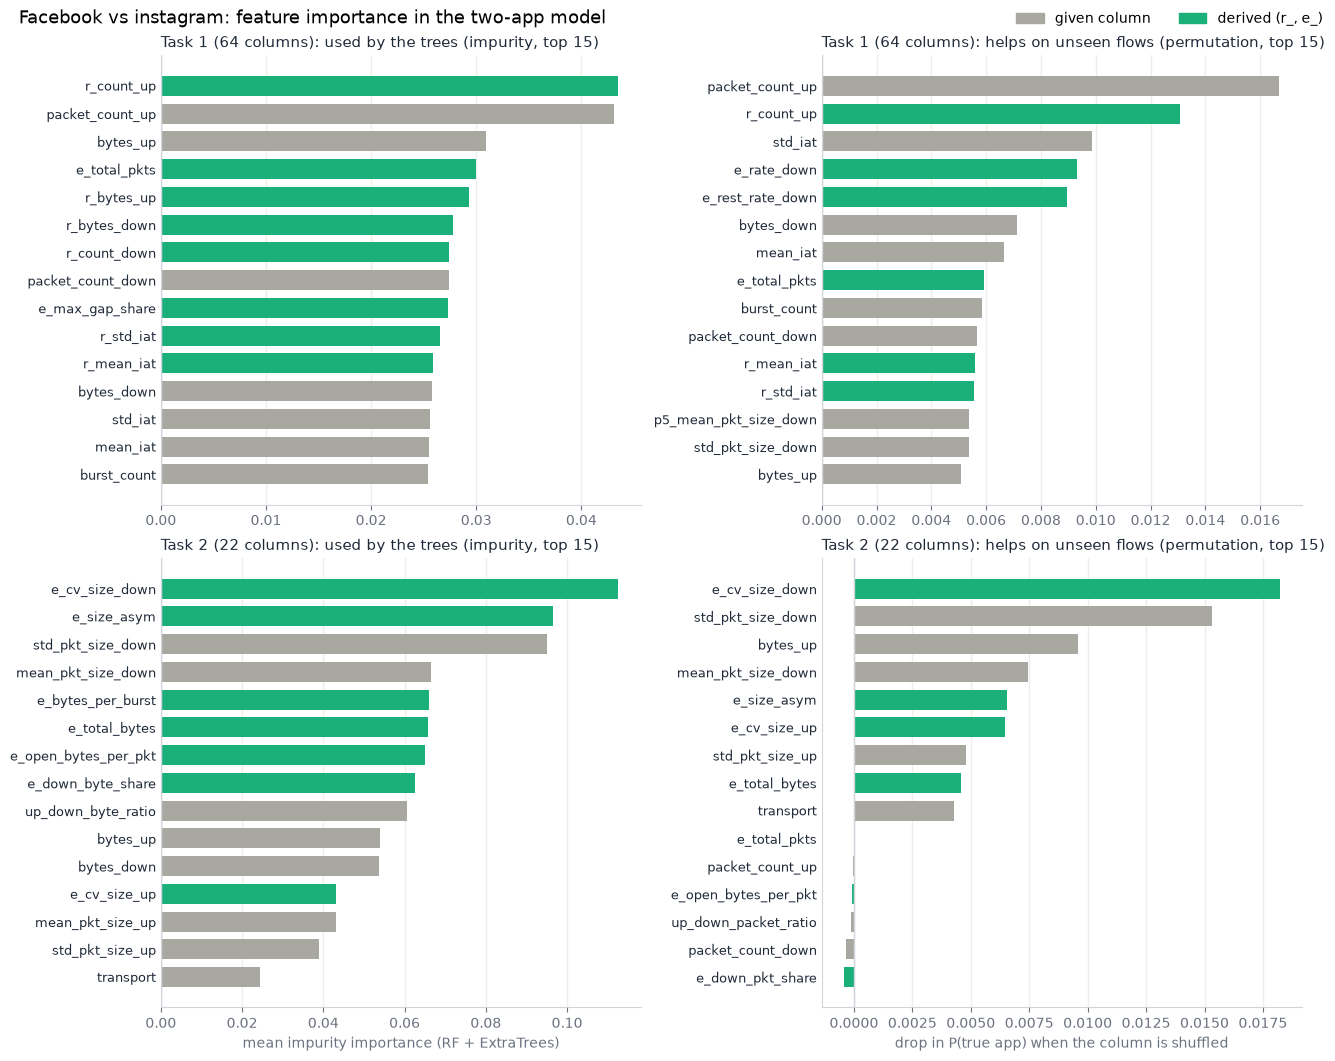

In [14]:
def _importance_fold(i, tr, te, X, yb, n_shuffles=5):
    m = SoftVote(seed=i).fit(X.iloc[tr], yb[tr])
    imp = np.mean([m.models_[0].feature_importances_, m.models_[1].feature_importances_], axis=0)  # RF, ExtraTrees
    Xte = X.iloc[te].reset_index(drop=True)
    fb = list(m.classes_).index("facebook")
    truth = (yb[te] == "facebook")
    p_true = lambda P: np.where(truth, P[:, fb], 1 - P[:, fb])
    base = p_true(m.predict_proba(Xte))
    rng = np.random.default_rng(i)
    blocks = []
    for c in X.columns:                      # every shuffled copy predicted in one call
        for _ in range(n_shuffles):
            B = Xte.copy()
            B[c] = rng.permutation(B[c].values)
            blocks.append(B)
    P = m.predict_proba(pd.concat(blocks, ignore_index=True))[:, fb].reshape(len(X.columns), n_shuffles, len(te))
    perm = (base - np.where(truth, P, 1 - P)).mean(axis=(1, 2))
    return imp, perm


def importance(X):
    splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=CV_SEED).split(X, yb)
    out = Parallel(n_jobs=-1)(delayed(_importance_fold)(i, tr, te, X, yb) for i, (tr, te) in enumerate(splits))
    return pd.DataFrame({"used by the trees": np.mean([o[0] for o in out], axis=0),
                         "helps on unseen flows": np.mean([o[1] for o in out], axis=0)}, index=X.columns)


IMP1, IMP2 = importance(F1m), importance(F2m)
DERIVED = "#1baf7a"  # green: derived columns; gray: given columns


def bars(ax, s, title, n=15):
    s = s.sort_values(ascending=False).head(n)[::-1]
    colors = [DERIVED if c.startswith(("e_", "r_")) else "#a8a7a0" for c in s.index]
    ax.barh(range(len(s)), s.values, color=colors, height=0.72)
    ax.set_yticks(range(len(s)), s.index, fontsize=9)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.axvline(0, color="#d1d5db", lw=1)
    ax.set_title(title, loc="left", fontsize=10.5, color=INK)
    ax.grid(axis="x", color="#eeeeec", lw=1)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(2, 2, figsize=(13, 10.5), constrained_layout=True)
for r, (task, imp) in enumerate([("Task 1 (64 columns)", IMP1), ("Task 2 (22 columns)", IMP2)]):
    bars(axes[r, 0], imp["used by the trees"], f"{task}: used by the trees (impurity, top 15)")
    bars(axes[r, 1], imp["helps on unseen flows"], f"{task}: helps on unseen flows (permutation, top 15)")
axes[1, 0].set_xlabel("mean impurity importance (RF + ExtraTrees)")
axes[1, 1].set_xlabel("drop in P(true app) when the column is shuffled")
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color="#a8a7a0", label="given column"), Patch(color=DERIVED, label="derived (r_, e_)")],
           loc="upper right", frameon=False, ncol=2)
fig.suptitle("Facebook vs instagram: feature importance in the two-app model", x=0.01, ha="left", fontsize=13)
plt.show()

In [15]:
# The same numbers as a table: share of all importance held by derived columns, and the top 10 by permutation
for task, imp, eng in (("Task 1", IMP1, ENG1), ("Task 2", IMP2, ENG2)):
    pos = imp["helps on unseen flows"].clip(lower=0)
    print(f"{task}: derived columns hold {imp.loc[eng, 'used by the trees'].sum() / imp['used by the trees'].sum():.0%} "
          f"of impurity importance and {pos[eng].sum() / pos.sum():.0%} of positive permutation importance")
pd.concat({"Task 1": IMP1.sort_values("helps on unseen flows", ascending=False).head(10).round(4).reset_index(),
           "Task 2": IMP2.sort_values("helps on unseen flows", ascending=False).head(10).round(4).reset_index()}, axis=1)

Task 1: derived columns hold 54% of impurity importance and 50% of positive permutation importance
Task 2: derived columns hold 53% of impurity importance and 46% of positive permutation importance


Task 1                                          \
               index used by the trees helps on unseen flows   
0    packet_count_up            0.0431                0.0167   
1         r_count_up            0.0435                0.0131   
2            std_iat            0.0256                0.0099   
3        e_rate_down            0.0165                0.0093   
4   e_rest_rate_down            0.0169                0.0090   
5         bytes_down            0.0258                0.0071   
6           mean_iat            0.0255                0.0067   
7       e_total_pkts            0.0300                0.0059   
8        burst_count            0.0254                0.0058   
9  packet_count_down            0.0274                0.0056   

               Task 2                                          
                index used by the trees helps on unseen flows  
0      e_cv_size_down            0.1125                0.0182  
1   std_pkt_size_down            0.0950                0.0153  
2            bytes_up            0.0540                0.0096  
3  mean_pkt_size_down            0.0664                0.0074  
4         e_size_asym            0.0966                0.0065  
5        e_cv_size_up            0.0432                0.0065  
6     std_pkt_size_up            0.0390                0.0048  
7       e_total_bytes            0.0657                0.0046  
8           transport            0.0244                0.0043  
9        e_total_pkts            0.0000                0.0000

In [16]:
# Single-column separation for every column, engineered ones included (AUC 0.5 = no signal; far from 0.5 = strong)
sep1 = (pd.Series({c: roc_auc_score(yb == "facebook", F1m[c]) for c in F1m.columns}))
sep2 = (pd.Series({c: roc_auc_score(yb == "facebook", F2m[c]) for c in F2m.columns}))
top = lambda s: s.reindex((s - 0.5).abs().sort_values(ascending=False).index).head(10).round(3).reset_index()
pd.concat({"Task 1 (64 columns)": top(sep1).set_axis(["column", "AUC"], axis=1),
           "Task 2 (22 columns)": top(sep2).set_axis(["column", "AUC"], axis=1)}, axis=1)

Task 1 (64 columns)          Task 2 (22 columns)       
               column    AUC                column    AUC
0          bytes_down  0.148        e_cv_size_down  0.225
1       e_total_bytes  0.158           e_size_asym  0.749
2   packet_count_down  0.163     std_pkt_size_down  0.258
3        r_count_down  0.163              bytes_up  0.275
4        r_bytes_down  0.167             transport  0.344
5            bytes_up  0.172         e_total_bytes  0.395
6        e_total_pkts  0.177  e_open_bytes_per_pkt  0.395
7          r_bytes_up  0.182     e_bytes_per_burst  0.400
8         burst_count  0.182      mean_pkt_size_up  0.404
9          r_count_up  0.191     e_down_byte_share  0.586

### What part 5 shows

- **Engineered features are used, but add no new information.** Derived columns take about half of the importance in
  both tasks: the trees happily split on `e_cv_size_down`, `e_rate_down` or `r_count_up`. But adding them changes the
  two-app AUC by +0.008 in Task 1 (7 of 10 repeats, noise) and −0.013 in Task 2. Engineered columns alone score about
  the same as the given columns alone. They carry the **same** information in another form: total bytes, rest-of-flow
  bytes and download rate all say "this flow is big".
- **Task 1's signal is volume and pace.** Upstream and downstream packet counts and bytes, the rest-of-flow counts,
  gap timing (`std_iat`, `mean_iat`) and download rate lead on unseen flows.
- **Task 2's signal is downstream packet-size spread.** `std_pkt_size_down` and its engineered form `e_cv_size_down`
  lead, then `bytes_up`. Even together they leave AUC near 0.59.
- **Fewer columns did better than more.** The post hoc 4-column volume model reached AUC 0.83 vs 0.80. With 24
  training flows per fold, every extra column is another chance to fit noise. That is a sign of too little data, not
  of a missing feature, and it would need a pre-registered test on fresh seeds before anyone trusts it.

## 6. Picking the best features inside stratified k-fold (nested selection)

Part 5 added all engineered features at once and let the trees choose. That is not a feature-selection test: with 24
training flows, a model given 64 columns spreads its splits over many weak and redundant ones. Here the features are
**selected**, and the selection is done **inside** each training fold, so the held-out flows never influence which
features are picked:

```text
outer: 5-fold stratified × 10 repeats on the 30 Meta flows (same folds as parts 2 and 5)
  └─ training part (24 flows) ─ inner: 3-fold stratified × 2 repeats ─ choose the features
                               └─ fit SoftVote on the chosen features → predict the 6 held-out flows
```

Two selection methods, both fixed before running:

- **Filter-k**: rank columns by single-column AUC on the inner training rows. The inner CV picks how many to keep
  (k = 1, 2, 3, 5, 8 or 12; ties go to the smaller k).
- **Forward**: start with no columns and add the column that raises the inner AUC most. Stop when the gain is below
  0.005 or 5 columns are chosen.

The inner model is a balanced random forest (100 trees), for speed. The final model on the chosen columns is the
usual SoftVote.

**Candidate columns**

- **Task 1:** the 64 columns of part 5.
- **Task 2:** the 22 columns of part 5 plus **8 exact opening sizes** decoded from the Task 2 statistics (experiment
  090): client and server first-packet sizes, smallest and largest packet per direction (`s_` prefix, −1 when they
  cannot be decoded). That makes 30 columns, all from the Task 2 file.

This cell takes several minutes (about 2,000 small forest fits per outer fold).

In [17]:
from sklearn.ensemble import RandomForestClassifier

from exp090_stamp_catalogue import NUM as STAMP_COLS, stamps

S2m = (pd.DataFrame([stamps(r) for r in X2_raw[meta].itertuples()])[STAMP_COLS]
       .astype(float).fillna(-1).add_prefix("s_").reset_index(drop=True))
CAND = {"Task 1": F1m, "Task 2": pd.concat([F2m, S2m], axis=1)}
for t, X in CAND.items():
    print(f"{t}: {X.shape[1]} candidate columns")


def _rf(seed):
    return RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=seed, n_jobs=1)


def _p_fb(m, X):
    return m.predict_proba(X)[:, list(m.classes_).index("facebook")]


def uni_rank(X, yy):
    """Columns sorted by single-column separation |AUC - 0.5| on these rows only."""
    a = np.array([roc_auc_score(yy == "facebook", X[c]) if X[c].nunique() > 1 else 0.5 for c in X.columns])
    return list(X.columns[np.argsort(-np.abs(a - 0.5), kind="stable")])


def inner_auc(X, yy, splits, seed, cols=None, k=None):
    """Mean over 2 repeats of the pooled inner AUC; columns fixed (`cols`) or top-k ranked on each inner training part."""
    aucs = []
    for r in range(2):
        p = np.zeros(len(yy))
        for tr, te in splits[3 * r:3 * r + 3]:
            c = cols if cols is not None else uni_rank(X.iloc[tr], yy[tr])[:k]
            p[te] = _p_fb(_rf(seed).fit(X.iloc[tr][c], yy[tr]), X.iloc[te][c])
        aucs.append(roc_auc_score(yy == "facebook", p))
    return float(np.mean(aucs))


def forward(X, yy, splits, seed, max_feats=5, min_gain=0.005):
    chosen, best = [], 0.5
    while len(chosen) < max_feats:
        scores = {c: inner_auc(X, yy, splits, seed, cols=chosen + [c]) for c in X.columns if c not in chosen}
        c, s = max(scores.items(), key=lambda kv: kv[1])
        if s < best + min_gain:
            break
        chosen.append(c)
        best = s
    return chosen


def _select_fold(i, tr, te, X, yy):
    Xtr, ytr = X.iloc[tr].reset_index(drop=True), yy[tr]
    sp = list(RepeatedStratifiedKFold(n_splits=3, n_repeats=2, random_state=i).split(Xtr, ytr))
    ks = [k for k in (1, 2, 3, 5, 8, 12) if k <= X.shape[1]]
    kscore = {k: inner_auc(Xtr, ytr, sp, i, k=k) for k in ks}
    k = max(ks, key=lambda k: (kscore[k], -k))
    picks = {"filter-k": uni_rank(Xtr, ytr)[:k]}
    picks["forward"] = forward(Xtr, ytr, sp, i) or picks["filter-k"][:1]
    out = {name: (cols, _p_fb(SoftVote(seed=i).fit(Xtr[cols], ytr), X.iloc[te][cols])) for name, cols in picks.items()}
    return te, k, out


def nested(X):
    splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=CV_SEED).split(X, yb)
    res = Parallel(n_jobs=-1)(delayed(_select_fold)(i, tr, te, X, yb) for i, (tr, te) in enumerate(splits))
    P = {m: np.zeros((10, len(yb))) for m in ("filter-k", "forward")}
    picks, ks = {m: [] for m in P}, []
    for i, (te, k, out) in enumerate(res):
        ks.append(k)
        for m, (cols, p) in out.items():
            P[m][i // 5, te] = p
            picks[m].append(cols)
    return P, picks, ks


NESTED = {t: nested(X) for t, X in CAND.items()}
# Control: Task 2 without the 8 decoded opening sizes, to see whether the gain comes from selection or from those sizes
NESTED_NO_S = nested(CAND["Task 2"].drop(columns=S2m.columns))

Task 1: 64 candidate columns
Task 2: 30 candidate columns


### Facebook vs instagram with selected features

Every row uses the same 50 outer folds. "Given columns" is the production feature set of each task (part 2), and the
Δ column compares each row with it, repeat by repeat. With 30 flows, |Δ AUC| below about 0.03 is noise.

In [18]:
ALL_CAND2 = binary_cv(CAND["Task 2"], yb)
rows = {}
for t, given, allc in (("Task 1", PROBS[T1_MAIN], FE_PROBS["Task 1: 34 given + 30 derived (rest + engineered)"]),
                       ("Task 2", PROBS[T2_MAIN], ALL_CAND2)):
    P, picks, ks = NESTED[t]
    ref = repeat_auc(given)
    n = CAND[t].shape[1]
    for name, Q, nf in ((f"given columns ({34 if t == 'Task 1' else 12})", given, None),
                        (f"all {n} candidates, no selection", allc, None),
                        ("nested filter-k", P["filter-k"], np.mean([len(c) for c in picks["filter-k"]])),
                        ("nested forward selection", P["forward"], np.mean([len(c) for c in picks["forward"]])),
                        *([("nested forward, without decoded sizes (22 candidates)", NESTED_NO_S[0]["forward"],
                            np.mean([len(c) for c in NESTED_NO_S[1]["forward"]])),
                           ("nested filter-k, without decoded sizes (22 candidates)", NESTED_NO_S[0]["filter-k"],
                            np.mean([len(c) for c in NESTED_NO_S[1]["filter-k"]]))] if t == "Task 2" else [])):
        d = repeat_auc(Q) - ref
        rows[(t, name)] = {**binary_scores(Q, yb), "columns used (mean)": "" if nf is None else f"{nf:.1f}",
                           "Δ AUC vs given (wins of 10)": "—" if np.allclose(d, 0) else f"{d.mean():+.3f} ({(d > 0).sum()})"}
pd.DataFrame(rows).T

facebook F1  \
Task 1 given columns (34)                                  0.618 ± 0.097   
       all 64 candidates, no selection                     0.618 ± 0.102   
       nested filter-k                                     0.622 ± 0.079   
       nested forward selection                            0.562 ± 0.089   
Task 2 given columns (12)                                  0.489 ± 0.065   
       all 30 candidates, no selection                     0.491 ± 0.066   
       nested filter-k                                     0.484 ± 0.080   
       nested forward selection                            0.591 ± 0.076   
       nested forward, without decoded sizes (22 candi...  0.491 ± 0.067   
       nested filter-k, without decoded sizes (22 cand...  0.490 ± 0.077   

                                                            instagram F1  \
Task 1 given columns (34)                                  0.799 ± 0.043   
       all 64 candidates, no selection                     0.790 ± 0.046   
       nested filter-k                                     0.781 ± 0.046   
       nested forward selection                            0.750 ± 0.049   
Task 2 given columns (12)                                  0.675 ± 0.044   
       all 30 candidates, no selection                     0.679 ± 0.045   
       nested filter-k                                     0.688 ± 0.051   
       nested forward selection                            0.778 ± 0.028   
       nested forward, without decoded sizes (22 candi...  0.743 ± 0.034   
       nested filter-k, without decoded sizes (22 cand...  0.709 ± 0.032   

                                                          macro F1 (2 apps)  \
Task 1 given columns (34)                                     0.708 ± 0.069   
       all 64 candidates, no selection                        0.704 ± 0.072   
       nested filter-k                                        0.701 ± 0.060   
       nested forward selection                               0.656 ± 0.063   
Task 2 given columns (12)                                     0.582 ± 0.053   
       all 30 candidates, no selection                        0.585 ± 0.054   
       nested filter-k                                        0.586 ± 0.056   
       nested forward selection                               0.685 ± 0.049   
       nested forward, without decoded sizes (22 candi...     0.617 ± 0.042   
       nested filter-k, without decoded sizes (22 cand...     0.599 ± 0.051   

                                                                     AUC  \
Task 1 given columns (34)                                  0.802 ± 0.047   
       all 64 candidates, no selection                     0.810 ± 0.046   
       nested filter-k                                     0.768 ± 0.034   
       nested forward selection                            0.715 ± 0.071   
Task 2 given columns (12)                                  0.596 ± 0.049   
       all 30 candidates, no selection                     0.591 ± 0.049   
       nested filter-k                                     0.587 ± 0.041   
       nested forward selection                            0.646 ± 0.038   
       nested forward, without decoded sizes (22 candi...  0.591 ± 0.055   
       nested filter-k, without decoded sizes (22 cand...  0.579 ± 0.048   

                                                          columns used (mean)  \
Task 1 given columns (34)                                                       
       all 64 candidates, no selection                                          
       nested filter-k                                                    9.2   
       nested forward selection                                           2.5   
Task 2 given columns (12)                                                       
       all 30 candidates, no selection                                          
       nested filter-k                                                    5.9   
       nested forward selection 

### Which features get selected, and how consistently?

If a feature is truly what separates facebook from instagram, the selection should pick it in most of the 50 outer
folds. If the picks change from fold to fold, the selection is chasing noise in 24 training flows. Bars count the
folds in which each column was selected (top 12 per method). Gray = given, green = derived (`e_` engineered, `r_`
rest-of-flow, `s_` decoded opening sizes).

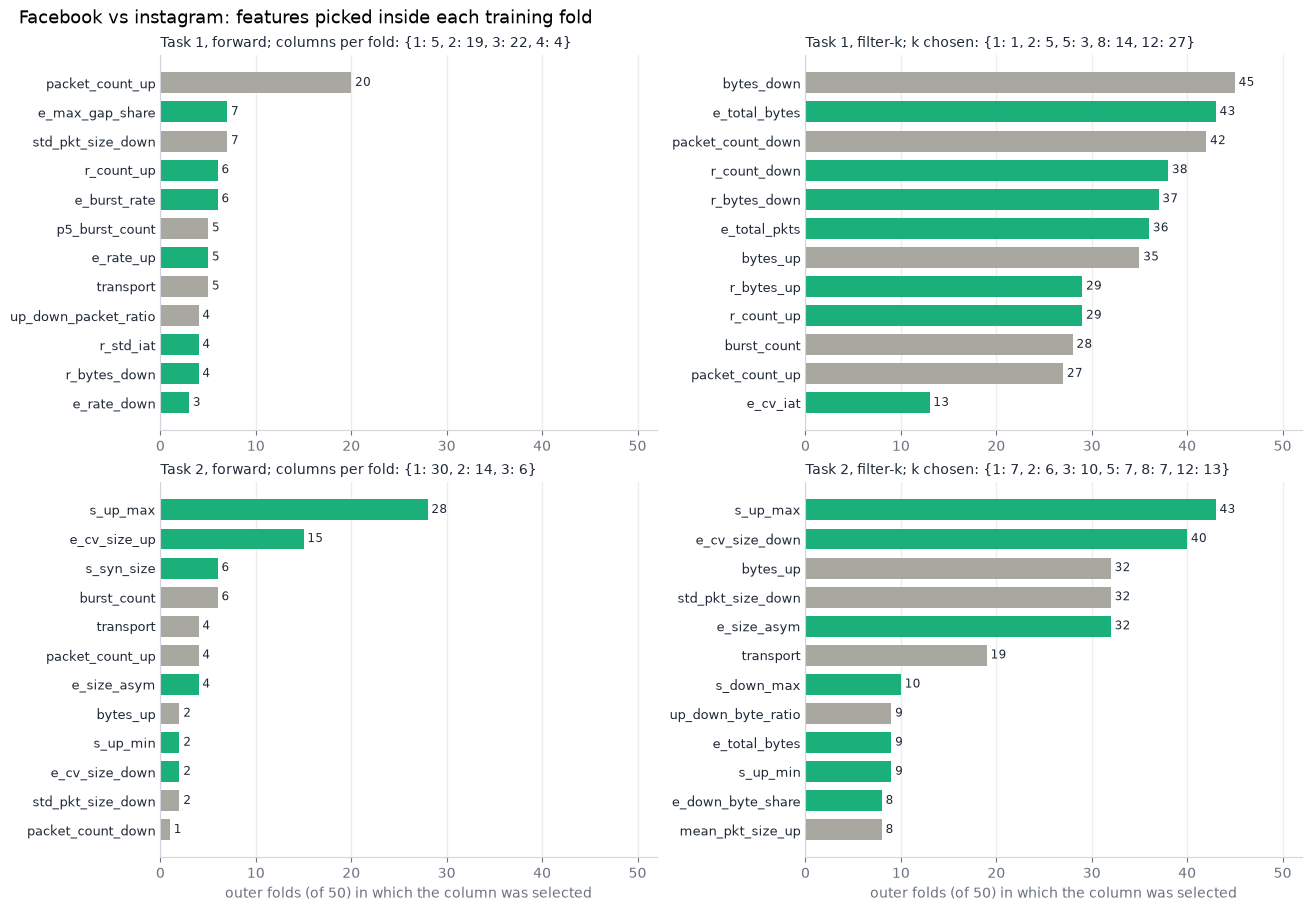

Task 1 forward: 46 different column sets in 50 folds; most common ['e_max_gap_share', 'packet_count_up'] (3 folds)
Task 2 forward: 23 different column sets in 50 folds; most common ['s_up_max'] (20 folds)


In [19]:
from collections import Counter

fig, axes = plt.subplots(2, 2, figsize=(13, 9), constrained_layout=True)
for r, t in enumerate(["Task 1", "Task 2"]):
    P, picks, ks = NESTED[t]
    for c, m in enumerate(["forward", "filter-k"]):
        cnt = pd.Series(Counter(col for cols in picks[m] for col in cols)).sort_values(ascending=False).head(12)[::-1]
        ax = axes[r, c]
        ax.barh(range(len(cnt)), cnt.values, height=0.72,
                color=[DERIVED if i.startswith(("e_", "r_", "s_")) else "#a8a7a0" for i in cnt.index])
        for y_, v in enumerate(cnt.values):
            ax.text(v + 0.4, y_, str(v), va="center", fontsize=8.5, color=INK)
        ax.set_yticks(range(len(cnt)), cnt.index, fontsize=9)
        ax.tick_params(axis="y", length=0, labelcolor=INK)
        ax.set_xlim(0, 52)
        extra = f"; k chosen: {dict(sorted(Counter(ks).items()))}" if m == "filter-k" else \
            f"; columns per fold: {dict(sorted(Counter(len(x) for x in picks[m]).items()))}"
        ax.set_title(f"{t}, {m}{extra}", loc="left", fontsize=10, color=INK)
        ax.grid(axis="x", color="#eeeeec", lw=1)
        ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel("outer folds (of 50) in which the column was selected")
fig.suptitle("Facebook vs instagram: features picked inside each training fold", x=0.01, ha="left", fontsize=13)
plt.show()

for t in ["Task 1", "Task 2"]:
    sets = [tuple(sorted(c)) for c in NESTED[t][1]["forward"]]
    top, n = Counter(sets).most_common(1)[0]
    print(f"{t} forward: {len(set(sets))} different column sets in 50 folds; most common {list(top)} ({n} folds)")

In [20]:
# What the most-picked Task 2 column looks like: the largest upstream packet of the opening, by app (Meta flows)
v = pd.DataFrame({"s_up_max": S2m.s_up_max.astype(int), "app": yb})
print(pd.crosstab(v.s_up_max, v.app).loc[lambda d: d.sum(axis=1) >= 1].sort_index().to_string())
print("\nWithout decoded sizes, forward selection picked:",
      Counter(c for cols in NESTED_NO_S[1]["forward"] for c in cols).most_common(6))

app       facebook  instagram
s_up_max                     
147              1          1
150              1          0
448              2          0
1294             0          1
1365             4          1
1367             3         16

Without decoded sizes, forward selection picked: [('e_cv_size_up', 22), ('transport', 14), ('burst_count', 7), ('e_size_asym', 7), ('bytes_up', 6), ('std_pkt_size_down', 6)]


### What part 6 shows

- **Task 1: selecting features hurts.** Filter-k loses 0.034 AUC and forward selection 0.087. Forward selection picked
  46 different column sets in 50 folds. Task 1's signal is spread over many correlated volume and timing columns, so
  the full set is best.
- **Task 2: one column carries the gain, `s_up_max`** (the largest upstream packet in the opening). With it, forward
  selection (1.5 columns on average) raises the two-app AUC from 0.60 to 0.65 (8 of 10 repeats) and the two-app macro
  F1 from 0.58 to 0.69 (facebook 0.49 → 0.59, instagram 0.68 → 0.78).
- **Without the decoded sizes, the AUC gain disappears** (−0.005). Using fewer columns still lifts instagram F1 to 0.74.
  The table above shows why: 1367 bytes = 16 of 19 instagram flows (and 3 facebook); 1365 bytes = 4 facebook, 1 instagram;
  448 bytes (a TCP first message) = facebook only.
- **Against the real Task 2 specialist** (an *unweighted* SoftVote, measured in part 7: two-app macro F1 0.636,
  AUC 0.607), forward selection *with* decoded sizes is still ahead (+0.05 macro F1, +0.04 AUC). *Without* them it
  is behind (0.617). The comparisons in this part used the balanced SoftVote of parts 2-5, which is weaker.
- ⚠️ **Compliance question before any use.** `s_up_max` is the size of the client's first message. For TCP that is
  the TLS ClientHello, whose length depends partly on the server name (experiment 090 notes this). The 2-byte QUIC
  difference (1365 vs 1367) may have the same cause; that is not verified. Challenge condition 3 forbids recovering
  domain strings, and `BACKLOG.md` lists size side channels used for that as off-limits. Using the size as a number
  does not recover the name, but it could be read as a side channel of it. The project treats ambiguous rules
  conservatively, so Sid and Charles must decide before any model uses it, and the technical report must disclose it.
- **Even if allowed, this is a hint, not a result.** It is one `cv_seed` on the pair stage only. The Task 2
  candidates included the 090 sizes, knowing that 090 had seen 1365/1367 lean facebook/instagram. A change would
  still have to pass in the full Task 2 pipeline (6-app macro F1), rule v2 on never-used seeds, and the upload rule.

## 7. kNN and a small neural network at the facebook/instagram stage

Task 2's pipeline has two steps: a 6-app `SoftVote` gives every flow an app, then every flow it calls facebook or
instagram is **re-decided by a specialist** trained only on facebook + instagram flows (an unweighted `SoftVote`,
experiment 014). Only that specialist decides facebook vs instagram, so it is the place to try a different model.

kNN was tried before only in other places: as a member of the **6-app** models (016, hurt facebook), as a third
Task 1 expert (064) and as a Task 1 facebook detector over all apps (081, facebook F1 0.24). A neural network was never
tried. This part tests both **at the specialist stage**, on the 30 Meta flows and the same 50 folds as parts 2-6.
Settings fixed before running:

| Model | Settings |
|---|---|
| `SoftVote`, unweighted | the current Task 2 specialist (reference) |
| `SoftVote`, balanced | the two-app model of parts 2-6 |
| kNN | k = 3 or 5, distance-weighted |
| MLP (neural network) | one hidden layer of 16 units, ReLU, L2 penalty α = 1.0 (strong, for 24 training flows), L-BFGS, seed = fold |
| `SoftVote` + kNN / + MLP / + both | the extra model as a 4th (5th) equal member of the probability average |

kNN and the MLP see `log1p` columns standardised **inside each training fold** (they depend on distances and scale;
trees do not). Columns: Task 2's 12 production columns, so no decoded sizes and no compliance question. Task 1's 34
columns are shown for comparison.

This scores the pair model on all 30 Meta flows. In the real pipeline the specialist only sees the flows the 6-app
model already sent to facebook or instagram, so a gain here is a necessary step, not proof.

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from models import Blend, et, lgbm, rf


def _scaled(est):
    """log1p of non-negative columns, then standardised on the training rows only (inside fit)."""
    return make_pipeline(FunctionTransformer(lambda A: np.log1p(np.clip(A, 0, None))), StandardScaler(), est)


def knn_member(k):
    def f(seed, class_weight=None):  # kNN has no class weights
        return _scaled(KNeighborsClassifier(n_neighbors=k, weights="distance"))
    return f


def mlp_member(seed, class_weight=None):  # sklearn's MLP has no class weights
    return _scaled(MLPClassifier(hidden_layer_sizes=(16,), alpha=1.0, solver="lbfgs", max_iter=2000, random_state=seed))


PAIR_MODELS = {
    "SoftVote, unweighted (current Task 2 specialist)": lambda s: Blend((rf, et, lgbm), seed=s, class_weight=None),
    "SoftVote, balanced (parts 2-6)": lambda s: SoftVote(seed=s),
    "kNN, k = 3": lambda s: Blend((knn_member(3),), seed=s, class_weight=None),
    "kNN, k = 5": lambda s: Blend((knn_member(5),), seed=s, class_weight=None),
    "MLP (16 units)": lambda s: Blend((mlp_member,), seed=s, class_weight=None),
    "SoftVote + kNN (k = 5)": lambda s: Blend((rf, et, lgbm, knn_member(5)), seed=s, class_weight=None),
    "SoftVote + MLP": lambda s: Blend((rf, et, lgbm, mlp_member), seed=s, class_weight=None),
    "SoftVote + kNN + MLP": lambda s: Blend((rf, et, lgbm, knn_member(5), mlp_member), seed=s, class_weight=None),
}


def _pair_fold(i, tr, te, X, yy, factory):
    m = factory(i).fit(X.iloc[tr], yy[tr])
    return te, _p_fb(m, X.iloc[te])


def pair_cv(X, factory):
    splits = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=CV_SEED).split(X, yb)
    out = Parallel(n_jobs=-1)(delayed(_pair_fold)(i, tr, te, X, yb, factory) for i, (tr, te) in enumerate(splits))
    P = np.zeros((10, len(yb)))
    for i, (te, p) in enumerate(out):
        P[i // 5, te] = p
    return P


def repeat_macro(P):
    return np.array([f1_score(yb, np.where(p >= 0.5, "facebook", "instagram"), labels=META, average="macro") for p in P])


PAIR_P = {(t, name): pair_cv(X, f) for t, X in (("Task 2", Xm2), ("Task 1", Xm1)) for name, f in PAIR_MODELS.items()}
rows = {}
for (t, name), P in PAIR_P.items():
    ref = PAIR_P[(t, "SoftVote, unweighted (current Task 2 specialist)")]
    da, dm = repeat_auc(P) - repeat_auc(ref), repeat_macro(P) - repeat_macro(ref)
    same = np.allclose(da, 0) and np.allclose(dm, 0)
    rows[(t, name)] = {**binary_scores(P, yb),
                       "Δ macro F1 vs current (wins of 10)": "—" if same else f"{dm.mean():+.3f} ({(dm > 0).sum()})",
                       "Δ AUC vs current (wins of 10)": "—" if same else f"{da.mean():+.3f} ({(da > 0).sum()})"}
pd.DataFrame(rows).T

facebook F1  \
Task 2 SoftVote, unweighted (current Task 2 specialist)  0.532 ± 0.064   
       SoftVote, balanced (parts 2-6)                    0.489 ± 0.065   
       kNN, k = 3                                        0.517 ± 0.061   
       kNN, k = 5                                        0.494 ± 0.086   
       MLP (16 units)                                    0.388 ± 0.117   
       SoftVote + kNN (k = 5)                            0.542 ± 0.064   
       SoftVote + MLP                                    0.529 ± 0.061   
       SoftVote + kNN + MLP                              0.534 ± 0.062   
Task 1 SoftVote, unweighted (current Task 2 specialist)  0.584 ± 0.079   
       SoftVote, balanced (parts 2-6)                    0.618 ± 0.097   
       kNN, k = 3                                        0.504 ± 0.075   
       kNN, k = 5                                        0.513 ± 0.060   
       MLP (16 units)                                    0.568 ± 0.096   
       SoftVote + kNN (k = 5)                            0.569 ± 0.086   
       SoftVote + MLP                                    0.596 ± 0.101   
       SoftVote + kNN + MLP                              0.578 ± 0.089   

                                                          instagram F1  \
Task 2 SoftVote, unweighted (current Task 2 specialist)  0.741 ± 0.036   
       SoftVote, balanced (parts 2-6)                    0.675 ± 0.044   
       kNN, k = 3                                        0.721 ± 0.038   
       kNN, k = 5                                        0.732 ± 0.031   
       MLP (16 units)                                    0.754 ± 0.034   
       SoftVote + kNN (k = 5)                            0.754 ± 0.037   
       SoftVote + MLP                                    0.737 ± 0.035   
       SoftVote + kNN + MLP                              0.744 ± 0.035   
Task 1 SoftVote, unweighted (current Task 2 specialist)  0.792 ± 0.029   
       SoftVote, balanced (parts 2-6)                    0.799 ± 0.043   
       kNN, k = 3                                        0.711 ± 0.048   
       kNN, k = 5                                        0.730 ± 0.042   
       MLP (16 units)                                    0.765 ± 0.040   
       SoftVote + kNN (k = 5)                            0.788 ± 0.034   
       SoftVote + MLP                                    0.797 ± 0.038   
       SoftVote + kNN + MLP                              0.786 ± 0.036   

                                                        macro F1 (2 apps)  \
Task 2 SoftVote, unweighted (current Task 2 specialist)     0.636 ± 0.048   
       SoftVote, balanced (parts 2-6)                       0.582 ± 0.053   
       kNN, k = 3                                           0.619 ± 0.047   
       kNN, k = 5                                           0.613 ± 0.057   
       MLP (16 units)                                       0.571 ± 0.074   
       SoftVote + kNN (k = 5)                               0.648 ± 0.048   
       SoftVote + MLP                                       0.633 ± 0.046   
       SoftVote + kNN + MLP                                 0.639 ± 0.047   
Task 1 SoftVote, unweighted (current Task 2 specialist)     0.688 ± 0.052   
       SoftVote, balanced (parts 2-6)                       0.708 ± 0.069   
       kNN, k = 3                                           0.608 ± 0.055   
       kNN, k = 5                                           0.621 ± 0.046   
       MLP (16 units)                                       0.666 ± 0.066   
       SoftVote + kNN (k = 5)                               0.679 ± 0.059   
       SoftVote + MLP                                       0.696 ± 0.069   
       SoftVote + kNN + MLP                                 0.682 ± 0.061   

                                                                   AUC  \
Task 2 SoftVote, unweighted (current Task 2 specialist)  0.607 ± 0.046   
       SoftVote, balanced (parts 2-6)                    0.596 ± 0.049   
       kN

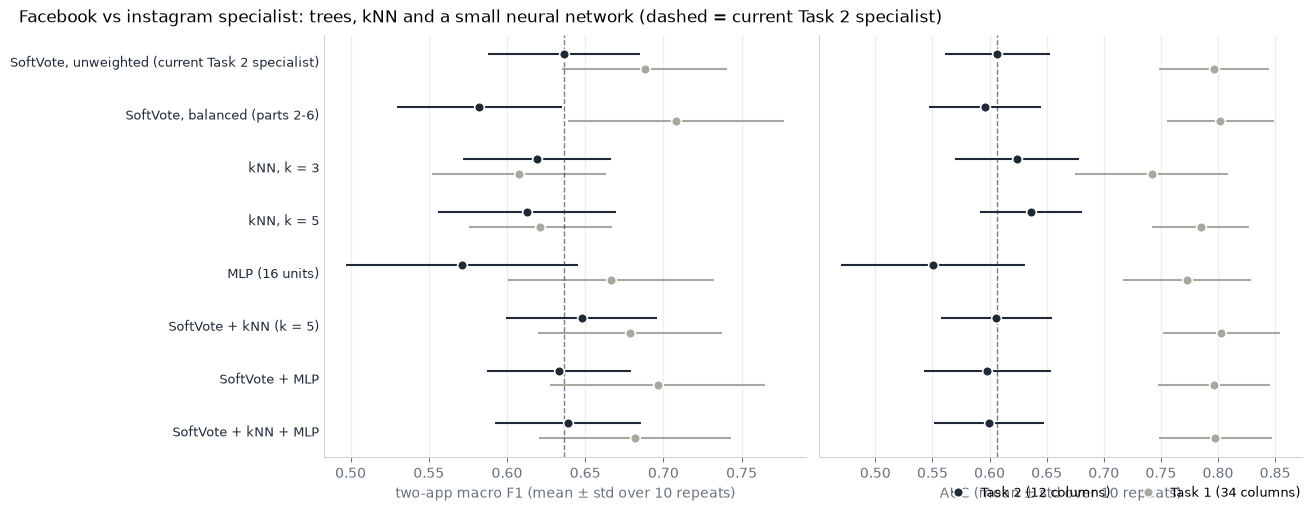

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0), sharey=True, constrained_layout=True)
names = list(PAIR_MODELS)[::-1]
for ax, (metric, fn) in zip(axes, (("two-app macro F1", repeat_macro), ("AUC", repeat_auc))):
    for t, color, dy in (("Task 2", INK, 0.14), ("Task 1", "#a8a7a0", -0.14)):
        vals = [fn(PAIR_P[(t, n)]) for n in names]
        mu, sd = np.array([v.mean() for v in vals]), np.array([v.std(ddof=1) for v in vals])
        ypos = np.arange(len(names)) + dy
        ax.errorbar(mu, ypos, xerr=sd, fmt="o", color=color, ms=7, mec="white", mew=1.2, elinewidth=1.5, capsize=0,
                    label=f"{t} ({12 if t == 'Task 2' else 34} columns)")
    ref = fn(PAIR_P[("Task 2", names[-1])]).mean()
    ax.axvline(ref, color=INK, lw=1, ls="--", alpha=0.6)
    ax.set_yticks(range(len(names)), names, fontsize=9)
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.set_xlabel(f"{metric} (mean ± std over 10 repeats)")
    ax.grid(axis="x", color="#eeeeec", lw=1)
    ax.set_axisbelow(True)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower right", frameon=False, fontsize=9, ncol=2)
fig.suptitle("Facebook vs instagram specialist: trees, kNN and a small neural network (dashed = current Task 2 specialist)",
             x=0.01, ha="left", fontsize=12)
plt.show()

### What part 7 shows

- **kNN ranks Meta flows slightly better than trees in Task 2, but decides worse.** With k = 5, AUC is 0.636 vs 0.607,
  higher in all 10 repeats, a small but consistent edge in *ordering*. At the 0.5 cut-off it gets fewer right
  (two-app macro F1 0.613 vs 0.636). Moving the cut-off toward facebook was tested before (043, 067) and was worse.
- **Adding kNN to the SoftVote** gives two-app macro F1 0.648 (+0.011, ahead in 4 of 10 repeats). That is within
  noise, and kNN's AUC edge disappears in the average.
- **The neural network is the weakest model** alone (0.571, AUC 0.550) and adds nothing to the SoftVote. 24 training
  flows are too few to learn weights from.
- **Task 1: neither helps.** Trees on 34 columns stay best.
- **The unweighted SoftVote, the real Task 2 specialist, beats the balanced one** used in parts 2-6 (0.636 vs 0.582),
  as experiment 012 found. Part 6 is corrected for this: only the version *with* the decoded first-packet size beats
  the real specialist.

## Summary: what this shows

**1. Facebook and instagram can be told apart from the whole flow, hardly from the first 5 packets.**
The two-app model reaches AUC about 0.80 to 0.83 on Task 1 columns but only about 0.60 on Task 2 columns (0.5 is a
coin toss). Adding opening timing makes Task 2 worse (0.54), matching experiment 007. The best Task 1 two-app macro
F1 is about 0.71 to 0.73.

**2. The signal is size: in this data, facebook flows are small and instagram flows are large.**
Facebook has fewer downstream bytes and packets, fewer upstream bytes and fewer bursts (single-column AUC 0.15 to
0.19, i.e. 0.81 to 0.85 the other way round). Several instagram flows download megabytes of media, while no facebook
flow exceeds about 100 kB downstream. In the first 5 packets only weak hints remain: `std_pkt_size_down`,
`bytes_up`, and `transport` (4 of the 11 facebook flows use TCP, while all but one instagram flow use UDP). ⚠️ One column ranks the 30 flows about as well as the whole two-app model. With only 30 flows, extra
columns add little beyond the size story. These are 30 flows, so every number here is uncertain.

**3. The 6-app production pipeline does better on facebook than the dedicated two-app model.**
Task 1 final F1 is 0.72 for facebook and 0.79 for instagram, against 0.62 and 0.80 for the two-app model. The 6-app
models learn from all 264 training flows per fold, and the facebook-specific stages add to that. ⚠️ Those stages were
designed and adopted on these same folds (`cv_seed` 2026), so their gains here are optimistic. On fresh seeds the
evidence was weaker: experiment 100 was BETTER on only 1 of 5 fresh seeds and was adopted as an exception.

**4. What each Task 1 stage contributes (per repeat, out of 30 Meta flows):**

| Stage | Effect on Meta flows |
|---|---|
| E1 whole-run expert | Does most of the work: facebook F1 0.63, instagram 0.78 |
| E2 opening expert | Weak alone (0.44 / 0.66), 9.6 facebook↔instagram swaps: the Task 2 problem |
| E3 rest-of-flow expert | Weak alone: sends 12 Meta flows outside Meta and pulls 8 others in. Useful only inside the gate's average |
| S1 two clerks | Identical to E1 on Meta flows, by design (the whole-run expert decides Meta calls) |
| S2 Meta gate | Facebook recall 0.59 → 0.72: brings back flows called google (e.g. `flow_000799`, `flow_001145`). Sent outside Meta 5.7 → 3.9 |
| S3 pair verifiers | Instagram precision 0.81 → 0.85, false Meta calls 3.3 → 2.5 |
| S4 exact-opening rule | No change on Meta flows (it never touches facebook/instagram) |
| S5 cross-task rescue | Facebook recall 0.72 → 0.79, sent outside Meta 3.9 → 3.0 |

**5. Task 2's specialist helps instagram, not facebook.** Swaps drop from 9.6 to 7.7 and instagram F1 rises from
0.66 to 0.73, but facebook recall stays at 0.42.

**6. Five flows defeat every stage.** `flow_000231` (facebook) is called x everywhere. `flow_000003` and
`flow_000216` (instagram) are called youtube. `flow_000379` and `flow_001185` (instagram) are called facebook. In
every view they look like another app, so no rule built from these columns is likely to fix them.

**7. The facebook score is fragile.** Each test fold has only 2 or 3 facebook flows. In Task 2, facebook F1 is 0 in
15 of 50 folds. This is the main reason the macro F1 moves so much between folds and between leaderboard uploads.

**8. Engineering features at the facebook/instagram stage adds no new information (part 5).** 30 derived columns
(ratios, rates, per-burst amounts, variability, opening-vs-rest contrasts) take half the importance but move the
two-app AUC by only +0.008 in Task 1 and −0.013 in Task 2. They restate "big flow vs small flow" in other forms. A
post hoc model on 4 volume columns did slightly better than all 34. The limit is the number of examples (11 facebook
flows), not the columns.

**9. Picking features inside stratified k-fold (part 6) helps Task 2 only through one column.** Nested forward
selection lifts the Task 2 two-app macro F1 to 0.69 (0.64 for the real, unweighted specialist; AUC 0.61 → 0.65). The gain comes from `s_up_max`, the
decoded size of the client's first packet (1367 bytes is mostly instagram). Without it the AUC gain disappears. In
Task 1, selection hurts. ⚠️ That size may depend on the server name's length (challenge condition 3), so using it
needs Sid's and Charles's decision first.

**10. kNN and a small neural network at the specialist stage do not beat the current specialist (part 7).** kNN
alone ranks facebook vs instagram slightly better (AUC 0.636 vs 0.607, all 10 repeats) but decides worse. SoftVote +
kNN is +0.011 two-app macro F1, within noise. The neural network is the weakest model. Selecting features without
the decoded size scores below the real specialist, so that idea is closed.